# Unit 09 — Data Cleaning & EDA Workflow
### Stage 1: Core Foundations | Data Science & AI Program

**Business scenario:** AdventureWorks — a fictional e-commerce company selling electronics, home products, and accessories.

**Audience:** Learners who completed Units 01–08  
**Environment:** Python 3 · Google Colab / Jupyter Notebook  
**Data policy:** Deterministic synthetic data generated in this notebook. No external downloads or API keys are required.

> **Instructor note:** This unit brings together Pandas and visualization skills to establish a repeatable workflow for assessing data quality and exploring a dataset before analysis or modeling. The goal is not to make every dataset look perfect; it is to make quality issues visible, document decisions, and avoid misleading conclusions.

## Learning outcomes

By the end of this unit, you should be able to:
- Explain why data quality checks are needed before analysis.
- Inspect a dataset and identify missing, duplicated, invalid, and inconsistent values.
- Distinguish a data error from a valid but unusual observation.
- Detect potential outliers and choose a defensible investigation strategy.
- Perform univariate and bivariate exploratory data analysis (EDA).
- Use descriptive statistics and visualizations to understand distributions and relationships.
- Explain the difference between correlation and causation.
- Document cleaning decisions, assumptions, and their possible effects.
- Produce a clean analysis-ready dataset without silently changing the source data.

### Prerequisites
Pandas data manipulation, NumPy, Matplotlib, Seaborn, descriptive statistics, filtering, grouping, and basic chart interpretation.

### Scope
This unit focuses on practical cleaning and EDA. It does not cover formal hypothesis testing, advanced imputation, feature selection, or model training. Those topics belong in later units.

## Table of contents
1. AdventureWorks dataset and data-quality questions
2. Establish a baseline
3. Missingness
4. Duplicate records
5. Invalid and inconsistent values
6. Outliers: detection versus decision
7. Univariate analysis
8. Bivariate analysis
9. Correlation versus causation
10. Document a cleaning workflow
11. Integrated EDA challenge
12. Instructor answer key
13. Summary and readiness checklist

## 1. AdventureWorks dataset and data-quality questions

The AdventureWorks analytics team receives an order-line export and must decide whether it is suitable for reporting. We will create a small synthetic dataset with realistic fields and deliberately introduced quality issues.

Each row represents one order line. In a production system, an order can contain several lines; a robust unique line key would normally include an order ID and a line ID.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

rng = np.random.default_rng(2026)

n = 80
product_names = ["Wireless Mouse", "USB-C Hub", "Mechanical Keyboard", "Desk Lamp",
                 "Headphones", "Laptop Stand", "Webcam", "Portable SSD"]
categories = {
    "Wireless Mouse": "Accessories",
    "USB-C Hub": "Accessories",
    "Mechanical Keyboard": "Electronics",
    "Desk Lamp": "Home",
    "Headphones": "Electronics",
    "Laptop Stand": "Accessories",
    "Webcam": "Electronics",
    "Portable SSD": "Electronics",
}
prices = {
    "Wireless Mouse": 24.99,
    "USB-C Hub": 34.00,
    "Mechanical Keyboard": 79.50,
    "Desk Lamp": 28.75,
    "Headphones": 59.99,
    "Laptop Stand": 39.00,
    "Webcam": 49.50,
    "Portable SSD": 89.00,
}

chosen_products = rng.choice(product_names, size=n)
quantities = rng.choice([1, 2, 3, 4], size=n, p=[0.55, 0.27, 0.13, 0.05])
unit_prices = np.array([prices[p] for p in chosen_products])
dates = rng.choice(pd.date_range("2026-09-01", periods=30, freq="D"), size=n)

raw_orders = pd.DataFrame({
    "order_id": [f"AW-{7001+i}" for i in range(n)],
    "order_date": dates,
    "customer": rng.choice(["Maya Chen", "Omar Saleh", "Lina Haddad", "Noah Reed", "Sara Nasser"], size=n),
    "product": chosen_products,
    "category": [categories[p] for p in chosen_products],
    "quantity": quantities,
    "unit_price": unit_prices,
    "status": rng.choice(["Shipped", "Processing", "Cancelled"], size=n, p=[0.62, 0.28, 0.10]),
})

raw_orders["line_total"] = raw_orders["quantity"] * raw_orders["unit_price"]

# Intentionally introduce quality issues for training.
raw_orders.loc[3, "customer"] = np.nan
raw_orders.loc[12, "unit_price"] = np.nan
raw_orders.loc[18, "quantity"] = -2
raw_orders.loc[24, "status"] = "shipped"          # inconsistent capitalization
raw_orders.loc[31, "category"] = "Electonic"      # invalid category label
raw_orders["order_date"] = raw_orders["order_date"].astype("object")
raw_orders.loc[42, "order_date"] = "not-a-date"   # invalid date text
raw_orders.loc[51, "unit_price"] = 9999.00        # unusual value to investigate
raw_orders = pd.concat([raw_orders, raw_orders.iloc[[6]]], ignore_index=True)

print("Raw dataset shape:", raw_orders.shape)
display(raw_orders.head(8))

Raw dataset shape: (81, 9)


,order_id,order_date,customer,product,category,quantity,unit_price,status,line_total
0,AW-7001,2026-09-30 00:00:00,Sara Nasser,Webcam,Electronics,2,49.50,Processing,99.00
1,AW-7002,2026-09-20 00:00:00,Lina Haddad,USB-C Hub,Accessories,1,34.00,Processing,34.00
2,AW-7003,2026-09-30 00:00:00,Omar Saleh,Wireless Mouse,Accessories,1,24.99,Shipped,24.99
3,AW-7004,2026-09-27 00:00:00,NaN,Laptop Stand,Accessories,2,39.00,Processing,78.00
4,AW-7005,2026-09-23 00:00:00,Maya Chen,Mechanical Keyboard,Electronics,1,79.50,Processing,79.50
5,AW-7006,2026-09-11 00:00:00,Omar Saleh,Desk Lamp,Home,1,28.75,Processing,28.75
6,AW-7007,2026-09-24 00:00:00,Lina Haddad,Wireless Mouse,Accessories,2,24.99,Shipped,49.98
7,AW-7008,2026-09-10 00:00:00,Noah Reed,Mechanical Keyboard,Electronics,1,79.50,Shipped,79.50


### Business questions
- Which columns have missing values?
- Are any records duplicated?
- Are quantities and prices valid for the business context?
- Are categories and statuses standardized?
- Are unusual prices genuine premium products, data-entry errors, or something else?
- Which variables may be related, and what can we responsibly conclude?

**Important:** The dataset intentionally contains known issues. Do not assume every unusual value must be deleted. The goal is to diagnose and document the issue before deciding what to do.

## 2. Establish a baseline

Before cleaning, preserve the raw data and record basic information. This helps explain what changed during preparation and supports reproducibility.

In [2]:
# Keep the raw source unchanged; work on a separate copy.
orders = raw_orders.copy(deep=True)

baseline = {
    "rows": len(orders),
    "columns": orders.shape[1],
    "exact_duplicate_rows": int(orders.duplicated().sum()),
    "missing_cells": int(orders.isna().sum().sum()),
}
print("Baseline profile:")
for metric, value in baseline.items():
    print(f"- {metric}: {value}")

print("\nData types:")
print(orders.dtypes)

Baseline profile:
- rows: 81
- columns: 9
- exact_duplicate_rows: 1
- missing_cells: 2

Data types:
order_id       object
order_date     object
customer       object
product        object
category       object
quantity        int64
unit_price    float64
status         object
line_total    float64
dtype: object


A baseline is a reference point, not a quality score by itself. A dataset can have no missing values and still contain invalid categories, impossible quantities, or incorrect dates.

## 3. Missingness

Missing values may mean different things: unknown, not collected, not applicable, or lost during data transfer. First measure missingness, then investigate why it occurred.

In [3]:
missing_summary = (
    orders.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)
missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(orders) * 100
).round(2)

display(missing_summary.sort_values("missing_percent", ascending=False))

,missing_count,missing_percent
customer,1,1.23
unit_price,1,1.23
order_id,0,0.00
product,0,0.00
order_date,0,0.00
category,0,0.00
quantity,0,0.00
status,0,0.00
line_total,0,0.00


### Visualize missingness

A simple bar chart can show which columns contain the most missing values. For small datasets, a table may be clearer than a complex visualization.

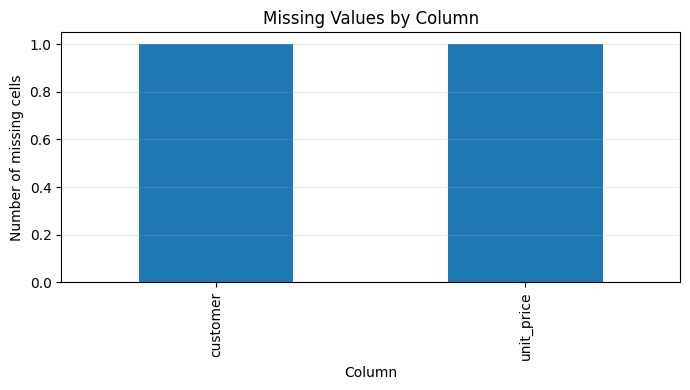

In [4]:
missing_counts = orders.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
missing_counts.plot(kind="bar", ax=ax)
ax.set_title("Missing Values by Column")
ax.set_xlabel("Column")
ax.set_ylabel("Number of missing cells")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Choose a strategy based on meaning

Possible strategies include:
- Investigate the source and recover the correct value.
- Keep the value missing when it is genuinely unknown.
- Fill with a transparent category such as `"Unknown"` for descriptive reporting.
- Remove a row only when the missing value prevents the intended analysis and removal is justified.
- Use statistical imputation only when its assumptions and downstream effects are understood.

Do not replace a missing price with zero: that would claim the product was free.

In [5]:
orders_missing_review = orders.copy()
orders_missing_review["customer"] = orders_missing_review["customer"].fillna("Unknown")

# Keep missing unit_price unresolved until it can be checked against a trusted source.
print("Missing customer values after label:", orders_missing_review["customer"].isna().sum())
print("Missing unit prices still requiring review:", orders_missing_review["unit_price"].isna().sum())

Missing customer values after label: 0
Missing unit prices still requiring review: 1


**Exercise 3A:** Identify the columns with missing values. Choose one field and explain whether you would recover, label, impute, or leave it missing—and why.

## 4. Duplicate records

Duplicates can inflate counts and totals. However, two records with the same order ID may be legitimate if one order contains several product lines. Define what one row represents before removing duplicates.

In [6]:
exact_duplicates = orders[orders.duplicated(keep=False)]
print("Rows participating in exact duplicates:", len(exact_duplicates))
display(exact_duplicates)

orders_no_exact_duplicates = orders.drop_duplicates().copy()
print("Rows before exact-duplicate removal:", len(orders))
print("Rows after exact-duplicate removal:", len(orders_no_exact_duplicates))

Rows participating in exact duplicates: 2


,order_id,order_date,customer,product,category,quantity,unit_price,status,line_total
6,AW-7007,2026-09-24 00:00:00,Lina Haddad,Wireless Mouse,Accessories,2,24.99,Shipped,49.98
80,AW-7007,2026-09-24 00:00:00,Lina Haddad,Wireless Mouse,Accessories,2,24.99,Shipped,49.98


Rows before exact-duplicate removal: 81
Rows after exact-duplicate removal: 80


`duplicated()` identifies repeated rows; `drop_duplicates()` removes them. This example removes only exact row duplicates. In real work, use a documented business key and investigate near-duplicates instead of assuming identical-looking records are always redundant.

**Exercise 4A:** Explain why dropping duplicates using `order_id` alone could be unsafe in an order-line dataset. What additional field would help identify a unique line?

## 5. Invalid and inconsistent values

Invalid values violate a known rule or expected domain. Inconsistent values represent the same concept in different formats. Examples include a negative quantity when returns are not represented that way, a misspelled category, inconsistent capitalization, or a date that cannot be parsed.

In [7]:
# 1) Inspect categorical values
print("Statuses:", sorted(orders["status"].dropna().astype(str).unique()))
print("\nCategories:", sorted(orders["category"].dropna().astype(str).unique()))

# 2) Check quantity and price rules
invalid_quantity = orders[orders["quantity"] <= 0]
invalid_price = orders[orders["unit_price"] < 0]

print("\nNon-positive quantities:", len(invalid_quantity))
display(invalid_quantity[["order_id", "product", "quantity"]])
print("Negative prices:", len(invalid_price))

# 3) Parse dates without hiding invalid values
orders_date_check = orders.copy()
orders_date_check["order_date_parsed"] = pd.to_datetime(
    orders_date_check["order_date"], errors="coerce"
)
invalid_dates = orders_date_check[orders_date_check["order_date_parsed"].isna()]
print("Unparseable dates:", len(invalid_dates))
display(invalid_dates[["order_id", "order_date"]])

Statuses: ['Cancelled', 'Processing', 'Shipped', 'shipped']

Categories: ['Accessories', 'Electonic', 'Electronics', 'Home']

Non-positive quantities: 1


,order_id,product,quantity
18,AW-7019,Wireless Mouse,-2


Negative prices: 0
Unparseable dates: 1


,order_id,order_date
42,AW-7043,not-a-date


### Standardize only when the intended mapping is clear

We know the valid status labels in this teaching scenario, so `"shipped"` can be normalized to `"Shipped"`. The misspelled category `"Electonic"` can be corrected because the product catalogue defines the valid category for each product. In real work, confirm mappings with a data owner or reference table.

In [ ]:
orders_clean = orders_no_exact_duplicates.copy()

# Standardize capitalization for known status labels.
orders_clean["status"] = orders_clean["status"].astype("string").str.strip().str.title()

# Parse dates; invalid values become NaT and remain visible for review.
orders_clean["order_date"] = pd.to_datetime(orders_clean["order_date"], errors="coerce")

# Use the product-to-category mapping as a trusted reference for category correction.
category_lookup = pd.Series(categories)
expected_category = orders_clean["product"].map(category_lookup)
category_mismatch = orders_clean["category"] != expected_category
print("Category values inconsistent with product reference:", int(category_mismatch.sum()))

orders_clean.loc[category_mismatch, "category"] = expected_category[category_mismatch]

display(orders_clean[["order_id", "order_date", "product", "category", "quantity", "unit_price", "status"]].head())

### Recalculate derived values after cleaning

`line_total` is derived from `quantity` and `unit_price`. If either input changes or is invalid, the derived value must be recalculated rather than trusted from the raw export.

In [ ]:
orders_clean["line_total"] = orders_clean["quantity"] * orders_clean["unit_price"]

# Flag invalid quantities for investigation rather than silently changing them.
orders_clean["invalid_quantity_flag"] = orders_clean["quantity"] <= 0

# Flag missing or unparseable dates for review.
orders_clean["invalid_date_flag"] = orders_clean["order_date"].isna()

print("Invalid quantity flags:", int(orders_clean["invalid_quantity_flag"].sum()))
print("Invalid date flags:", int(orders_clean["invalid_date_flag"].sum()))

**Exercise 5A:** Create a check for prices that are missing or not positive. Explain why a suspicious value should be flagged and investigated rather than automatically replaced.

## 6. Outliers: detection versus decision

An outlier is an observation that is unusually far from much of the data. It may be a data error, a rare but valid event, or a result of a different process. Detection is not the same as deciding to remove it.

A common exploratory method is the IQR rule:
- `Q1`: 25th percentile.
- `Q3`: 75th percentile.
- `IQR = Q3 - Q1`.
- Potential outliers fall below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

This is a flagging rule, not a universal definition of invalid data.

In [ ]:
price_values = orders_clean["unit_price"].dropna()
q1 = price_values.quantile(0.25)
q3 = price_values.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

potential_price_outliers = orders_clean[
    orders_clean["unit_price"].notna() &
    (
        (orders_clean["unit_price"] < lower_bound) |
        (orders_clean["unit_price"] > upper_bound)
    )
]

print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Potential outlier bounds: {lower_bound:.2f} to {upper_bound:.2f}")
display(potential_price_outliers[["order_id", "product", "unit_price"]])

### Visual inspection with a boxplot

A boxplot can help show the spread and potential outliers. The chart's whiskers follow a convention; they do not prove that any point is wrong.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=orders_clean, x="unit_price", ax=ax, color="steelblue")
ax.set_title("Unit Price — Potential Outlier Review")
ax.set_xlabel("Unit price (USD)")
plt.tight_layout()
plt.show()

### Make a documented decision

The synthetic dataset contains a price of `$9,999` for a product whose trusted catalogue price is known. In this exercise, the catalogue is an authoritative reference, so the row can be flagged as a price mismatch. Do not generalize this rule to real businesses without confirming whether prices can vary by promotion, supplier, or date.

In [ ]:
orders_clean["catalogue_price"] = orders_clean["product"].map(prices)
orders_clean["price_mismatch_flag"] = (
    orders_clean["unit_price"].notna() &
    ~np.isclose(
        orders_clean["unit_price"].fillna(0),
        orders_clean["catalogue_price"].fillna(0),
        rtol=0,
        atol=0.01
    )
)

display(orders_clean.loc[
    orders_clean["price_mismatch_flag"],
    ["order_id", "product", "unit_price", "catalogue_price"]
])

**Exercise 6A:** Use the IQR rule to flag potential outliers in `line_total`. Choose one flagged row and list two checks you would perform before excluding or changing it.

## 7. Univariate analysis

Univariate analysis studies one variable at a time. It helps answer questions about typical values, spread, category frequency, missingness, and unusual observations.

For numeric variables, inspect descriptive statistics and distributions. For categorical variables, inspect counts and proportions.

In [ ]:
# Numeric summaries
display(orders_clean[["quantity", "unit_price", "line_total"]].describe())

# Categorical frequency
status_counts = orders_clean["status"].value_counts(dropna=False)
status_percent = (orders_clean["status"].value_counts(normalize=True, dropna=False) * 100).round(1)
status_summary = pd.DataFrame({
    "count": status_counts,
    "percent": status_percent
})
display(status_summary)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=orders_clean, x="line_total", bins=12, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Order-Line Value")
axes[0].set_xlabel("Line total (USD)")

sns.countplot(data=orders_clean, x="status", order=orders_clean["status"].value_counts().index, ax=axes[1], color="steelblue")
axes[1].set_title("Order-Line Records by Status")
axes[1].set_xlabel("Status")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**Interpretation prompts**
- Is `line_total` concentrated in a narrow range or spread widely?
- Which status is most frequent?
- Does the price outlier affect the numeric summary?
- Why should counts of order lines not automatically be described as counts of unique orders?

## 8. Bivariate analysis

Bivariate analysis explores two variables at a time. It can compare a numeric variable across categories or examine the relationship between two numeric variables.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(data=orders_clean, x="category", y="line_total", ax=axes[0])
axes[0].set_title("Line Value by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Line total (USD)")
axes[0].tick_params(axis="x", rotation=20)

sns.scatterplot(data=orders_clean, x="quantity", y="line_total", hue="category", ax=axes[1])
axes[1].set_title("Quantity vs. Line Value")
axes[1].set_xlabel("Quantity")
axes[1].set_ylabel("Line total (USD)")

plt.tight_layout()
plt.show()

### Compare groups with summary statistics

Charts are useful, but a small summary table can make group differences easier to quantify.

In [ ]:
category_eda = (
    orders_clean.groupby("category", dropna=False)
    .agg(
        records=("order_id", "count"),
        median_line_total=("line_total", "median"),
        mean_line_total=("line_total", "mean"),
        total_units=("quantity", "sum")
    )
    .sort_values("median_line_total", ascending=False)
)
display(category_eda)

**Interpretation prompt:** Which category has the highest median line value in this sample? How might product mix and quantity explain the result? Avoid treating a descriptive difference as proof that category causes higher order value.

**Exercise 8A:** Explore `status` versus `category` using a cross-tabulation. What does the table tell you, and what does it not tell you?

In [ ]:
status_by_category = pd.crosstab(orders_clean["category"], orders_clean["status"], margins=True)
display(status_by_category)

## 9. Correlation versus causation

Correlation describes how two variables vary together. Causation means that changing one variable produces a change in another, under a defensible causal argument.

Correlation alone cannot prove causation because:
- A third variable may influence both.
- The relationship may be partly defined by a formula.
- Selection effects or data quality issues may distort the pattern.
- The sample may be small or unrepresentative.

In this dataset, `line_total = quantity × unit_price`. A relationship between these variables is expected by construction, so it is not evidence that changing price will cause a particular business outcome.

In [ ]:
numeric_columns = orders_clean[["quantity", "unit_price", "line_total"]]
corr = numeric_columns.corr()

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="coolwarm", ax=ax)
ax.set_title("Correlation Between Numeric Order-Line Variables")
plt.tight_layout()
plt.show()

display(corr)

**Discussion:** What additional data or study design would be needed to test whether a price change affects purchase quantity? Consider promotions, product differences, seasonality, availability, and customer behavior.

## 10. Document a cleaning workflow

A professional cleaning workflow should be reproducible and explain the reason for each transformation. Keep the raw source unchanged and create a prepared version for analysis.

A simple cleaning log can record the issue, the action, and the rationale.

In [ ]:
cleaning_log = pd.DataFrame([
    {
        "issue": "Exact duplicate row",
        "action": "Removed exact duplicate rows",
        "reason": "Repeated complete record can inflate counts and totals"
    },
    {
        "issue": "Missing customer",
        "action": "Used 'Unknown' in a reporting copy",
        "reason": "Preserves the record without inventing a customer identity"
    },
    {
        "issue": "Invalid date string",
        "action": "Parsed with errors='coerce' and flagged NaT",
        "reason": "Keeps the issue visible for follow-up"
    },
    {
        "issue": "Category spelling mismatch",
        "action": "Mapped category from product reference",
        "reason": "Trusted product-to-category mapping is available"
    },
    {
        "issue": "Suspicious unit price",
        "action": "Flagged mismatch against catalogue price",
        "reason": "Requires verification before correction"
    },
    {
        "issue": "Non-positive quantity",
        "action": "Flagged for review; not silently changed",
        "reason": "May be invalid or may reflect an unmodeled business process"
    }
])

display(cleaning_log)

### Create an analysis-ready view

For this training workflow, keep only rows that pass selected checks. The criteria are explicit and intended for demonstration; real projects should agree on them with the business owner. We will not overwrite the raw dataset.

In [ ]:
analysis_ready = orders_clean.copy()

# Apply the documented reporting label for unknown customer names.
analysis_ready["customer"] = analysis_ready["customer"].fillna("Unknown")

# Apply only the documented training rules:
# - Exclude non-positive quantities from this particular order-line analysis.
# - Exclude rows with invalid dates.
# - Exclude missing prices and prices that do not match the trusted catalogue.
analysis_ready = analysis_ready[
    (analysis_ready["quantity"] > 0) &
    (analysis_ready["order_date"].notna()) &
    (analysis_ready["unit_price"].notna()) &
    (~analysis_ready["price_mismatch_flag"])
].copy()

# Recalculate derived values after filtering.
analysis_ready["line_total"] = (
    analysis_ready["quantity"] * analysis_ready["unit_price"]
)

print("Raw rows:", len(raw_orders))
print("After exact duplicate removal:", len(orders_no_exact_duplicates))
print("Analysis-ready rows:", len(analysis_ready))
print("Remaining missing cells:", int(analysis_ready.isna().sum().sum()))
display(analysis_ready.head())

**Important:** An analysis-ready dataset is ready for a specific analysis, not universally clean for every possible use. Excluding rows changes the population being analyzed; record the criteria and report the number of rows affected.

In [ ]:
output_dir = Path("adventureworks_data")
output_dir.mkdir(exist_ok=True)
cleaned_path = output_dir / "adventureworks_unit09_analysis_ready.csv"
log_path = output_dir / "adventureworks_unit09_cleaning_log.csv"

analysis_ready.to_csv(cleaned_path, index=False)
cleaning_log.to_csv(log_path, index=False)

reloaded = pd.read_csv(cleaned_path)
print("Saved analysis-ready dataset:", cleaned_path)
print("Saved cleaning log:", log_path)
print("Reloaded shape:", reloaded.shape)

## 11. Integrated EDA challenge

### Scenario
The AdventureWorks analytics lead needs a short quality assessment before using the order-line export in a report.

### Tasks
1. Profile the raw data: shape, data types, missingness, and exact duplicates.
2. Identify invalid dates, non-positive quantities, inconsistent categories, and suspicious prices.
3. Use descriptive statistics and at least two plots to understand distributions.
4. Explore one numeric-versus-numeric relationship and one numeric-versus-category comparison.
5. Explain why an outlier flag does not automatically justify deletion.
6. Create a cleaning log with issue, action, and rationale.
7. Create an analysis-ready copy using explicit rules.
8. Export the prepared dataset and cleaning log.
9. Write three findings and one limitation for each finding.

### Acceptance criteria
- Preserve the raw dataset.
- Separate detection from correction.
- Do not silently replace missing or suspicious values.
- Use the product catalogue only where its role as a trusted reference is explicit.
- Distinguish order-line counts from unique-order counts.
- Do not infer causation from correlation.
- State how cleaning rules affect the resulting dataset.

## 12. Instructor answer key

> **Instructor use:** Allow learners to complete the challenge first. This solution demonstrates one defensible workflow; it is not the only valid approach.

In [ ]:
# Reference solution — compact quality report
quality_report = pd.DataFrame({
    "check": [
        "Raw rows",
        "Exact duplicate rows",
        "Missing cells",
        "Non-positive quantities",
        "Unparseable dates",
        "Catalogue price mismatches"
    ],
    "count": [
        len(raw_orders),
        int(raw_orders.duplicated().sum()),
        int(raw_orders.isna().sum().sum()),
        int((orders_clean["quantity"] <= 0).sum()),
        int(orders_clean["order_date"].isna().sum()),
        int(orders_clean["price_mismatch_flag"].sum())
    ]
})
display(quality_report)

# Summary after applying the documented training rules
final_category_summary = (
    analysis_ready.groupby("category", as_index=False)
    .agg(
        order_line_count=("order_id", "count"),
        units=("quantity", "sum"),
        total_line_value=("line_total", "sum")
    )
    .sort_values("total_line_value", ascending=False)
)
display(final_category_summary)

print("Prepared rows:", len(analysis_ready))
print("Prepared missing cells:", int(analysis_ready.isna().sum().sum()))